In [11]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf


In [12]:
IMG_SIZE = (28, 28)
BATCH_SIZE = 64
DATASET_DIR = "dataset/"

# 80% Training, 20% Validation
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE
)



Found 10071 files belonging to 19 classes.
Using 8057 files for training.
Found 10071 files belonging to 19 classes.
Using 2014 files for validation.
Loaded 19 classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'add', 'dec', 'div', 'eq', 'mul', 'sub', 'x', 'y', 'z']


In [ ]:
class_names = train_ds.class_names
print(f"Loaded {len(class_names)} classes: {class_names}")

with open("classes.json", "w") as f:
    json.dump(class_names, f)

In [13]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomTranslation(height_factor=0.08, width_factor=0.08),
    tf.keras.layers.RandomRotation(0.04),
    tf.keras.layers.RandomZoom(0.08)
])

In [15]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),
    
    # Inverts white-background dataset into MNIST/canvas black-background
    tf.keras.layers.Rescaling(scale=-1.0 / 255.0, offset=1.0),
    
    data_augmentation,
    
    tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    
    tf.keras.layers.Conv2D(64, kernel_size=(3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    
    # Dynamic output for 19 classes
    tf.keras.layers.Dense(len(class_names))
])



In [16]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 19)             │         2,451 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,803 (1.61 MB)

 Trainable params: 422,803 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

Epoch 1/12


/Users/adrianhuang/Documents/JUPYTER_FILES/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


126/126 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.3917 - loss: 2.0329 - val_accuracy: 0.7160 - val_loss: 0.9599
Epoch 2/12
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6720 - loss: 1.0854 - val_accuracy: 0.7979 - val_loss: 0.6700
Epoch 3/12
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7545 - loss: 0.8004 - val_accuracy: 0.8724 - val_loss: 0.4294
Epoch 4/12
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8089 - loss: 0.6335 - val_accuracy: 0.9017 - val_loss: 0.3435
Epoch 5/12
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8276 - loss: 0.5605 - val_accuracy: 0.9076 - val_loss: 0.3046
Epoch 6/12
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8463 - loss: 0.5057 - val_accuracy: 0.8908 - val_loss: 0.3432
Epoch 7/12
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8569 - loss: 0.4594 - val_accuracy: 0.9290 - val_loss: 0.2334
Epoch 8/12
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8786 - loss: 0.3976 - val_accuracy: 0.927

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12
)

In [18]:
val_loss, val_acc = model.evaluate(val_ds, verbose=2)
print(f"\nFinal Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Final Validation Loss:     {val_loss:.4f}")


32/32 - 0s - 5ms/step - accuracy: 0.9508 - loss: 0.1606

Final Validation Accuracy: 95.08%
Final Validation Loss:     0.1606


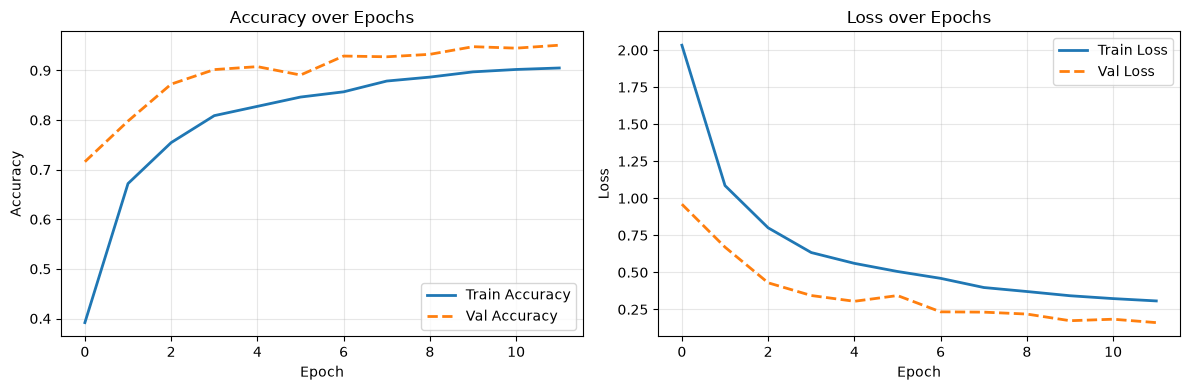

In [19]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2, linestyle='--')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Val Loss', linewidth=2, linestyle='--')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


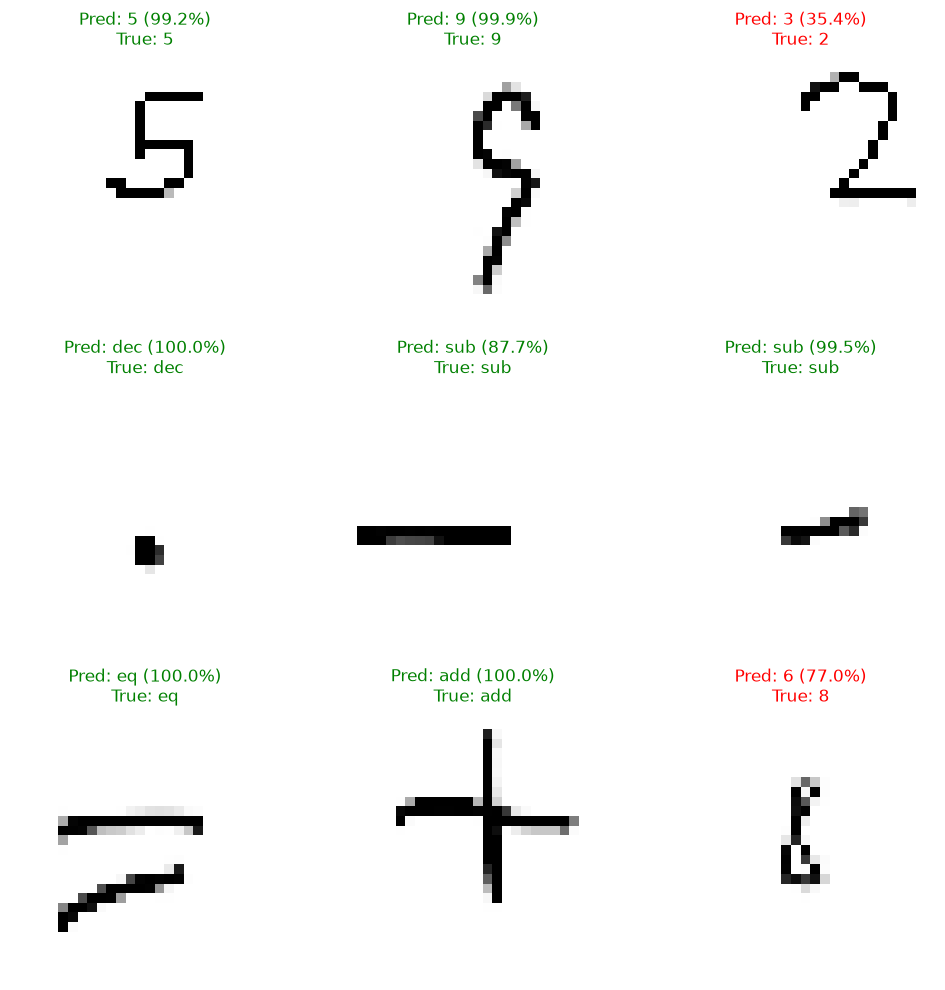

In [22]:
# Test on a batch of validation images
for images, labels in val_ds.take(1):
    predictions = model.predict(images)
    probabilities = tf.nn.softmax(predictions).numpy()

    plt.figure(figsize=(10, 10))
    for i in range(min(9, len(images))):
        pred_idx = np.argmax(probabilities[i])
        pred_label = class_names[pred_idx]
        true_label = class_names[labels[i].numpy()]
        confidence = probabilities[i][pred_idx] * 100

        ax = plt.subplot(3, 3, i + 1)
        # Display image (shows black stroke on white as stored in dataset)
        plt.imshow(images[i].numpy().squeeze(), cmap="gray")
        
        # Title is Green if correct, Red if wrong
        color = "green" if pred_label == true_label else "red"
        plt.title(f"Pred: {pred_label} ({confidence:.1f}%)\nTrue: {true_label}", color=color)
        plt.axis("off")
        
    plt.tight_layout()
    plt.show()
    break


In [20]:
model.save("mnist_modelv4.keras")
